# RabTech Academy — Task 3: Advanced Statistical Analysis & Hypothesis Testing

**Research topic:** Study time and final mathematics grades in the UCI Student Performance dataset.

This notebook performs normality tests, two-group tests, one-way and two-way ANOVA, Tukey HSD, confidence intervals, and distribution plots.

> This is observational data. Statistical association does not establish causation. Run all cells from top to bottom before reporting results.


## 1. Setup and load the data

Download the official UCI dataset and place `student-mat.csv` in `data/raw/`. The notebook stops if the file is missing; it does not generate fake research results.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists() and (ROOT.parent / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "student-mat.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Download the official UCI Student Performance dataset "
        "and put student-mat.csv in data/raw/."
    )
df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Research question and hypotheses

**Research question:** Are final mathematics grades associated with reported study time?

**Primary two-group comparison:** lower study-time categories (1–2) versus higher categories (3–4).

- **H₀:** The mean final grade (`G3`) is equal in the lower- and higher-study-time groups.
- **H₁:** The mean final grade differs between the groups.
- **Significance level:** α = 0.05.
- **Outcome:** `G3`, final mathematics grade (0–20).
- **Exclusions:** rows missing/invalid `studytime`, `G3`, or `sex`; studytime must be 1–4.
- This observational analysis cannot establish causation.


In [3]:
required = {"studytime", "G3", "sex"}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {sorted(missing_cols)}")
analysis = df[["studytime", "G3", "sex"]].copy()
for col in ["studytime", "G3"]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")
rows_before = len(analysis)
analysis = analysis.dropna(subset=["studytime", "G3", "sex"])
analysis = analysis[analysis["studytime"].isin([1, 2, 3, 4])].copy()
analysis["study_group"] = np.where(analysis["studytime"].isin([3, 4]), "Higher (3–4)", "Lower (1–2)")
analysis["studytime_cat"] = analysis["studytime"].astype(int).astype(str)
analysis["sex"] = analysis["sex"].astype("category")
print(f"Rows before filtering: {rows_before}; retained: {len(analysis)}; excluded: {rows_before-len(analysis)}")
display(analysis.head())


Rows before filtering: 395; retained: 395; excluded: 0


,studytime,G3,sex,study_group,studytime_cat
0,2,6,F,Lower (1–2),2
1,2,6,F,Lower (1–2),2
2,2,10,F,Lower (1–2),2
3,3,15,F,Higher (3–4),3
4,2,10,F,Lower (1–2),2


## 3. Descriptive statistics and distribution plots

Summarize final grades by study-time group and visualize their distributions.

,n,mean,sd,median,q1,q3
study_group,,,,,,
Higher (3–4),92,11.358696,4.807461,12.0,9.75,15.0
Lower (1–2),303,10.128713,4.479527,10.0,8.00,13.0


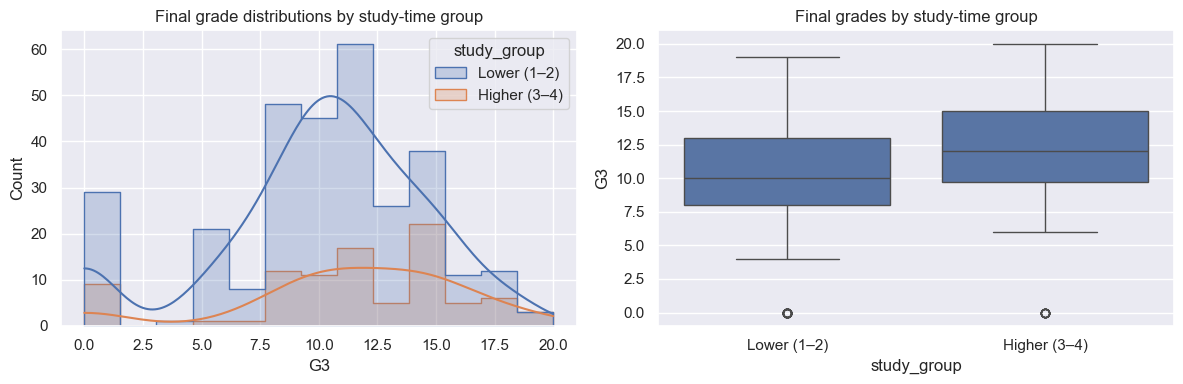

In [4]:
summary = analysis.groupby("study_group", observed=True)["G3"].agg(
    n="count", mean="mean", sd="std", median="median",
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
)
display(summary)
sns.set_theme()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=analysis, x="G3", hue="study_group", kde=True, element="step", ax=axes[0])
axes[0].set_title("Final grade distributions by study-time group")
sns.boxplot(data=analysis, x="study_group", y="G3", ax=axes[1])
axes[1].set_title("Final grades by study-time group")
plt.tight_layout()
plt.show()


## 4. Normality tests: Shapiro–Wilk and Kolmogorov–Smirnov

- **Shapiro–Wilk H₀:** the sample is from a normal distribution.
- **Kolmogorov–Smirnov:** compares standardized grades with a standard normal distribution. Its p-value is approximate because mean and standard deviation are estimated from the same sample; interpret cautiously.
- At α = 0.05, p < 0.05 is evidence against normality. A larger p-value does not prove normality.


In [5]:
normality_rows = []
for group, sub in analysis.groupby("study_group", observed=True):
    x = sub["G3"].dropna().to_numpy(dtype=float)
    shapiro = stats.shapiro(x)
    z = (x - x.mean()) / x.std(ddof=1)
    ks = stats.kstest(z, "norm")
    normality_rows.append({
        "group": group, "n": len(x),
        "Shapiro-Wilk statistic": shapiro.statistic,
        "Shapiro-Wilk p": shapiro.pvalue,
        "KS statistic (standardized)": ks.statistic,
        "KS p (approximate)": ks.pvalue
    })
display(pd.DataFrame(normality_rows))


,group,n,Shapiro-Wilk statistic,Shapiro-Wilk p,KS statistic (standardized),KS p (approximate)
0,Higher (3–4),92,0.902168,4.099414e-06,0.138733,0.052450
1,Lower (1–2),303,0.931525,1.349347e-10,0.135403,0.000026


## 5. Two-sample t-test and Mann–Whitney U test

Two-sided hypotheses:
- **H₀ for Welch t-test:** population mean grades are equal.
- **H₁:** population mean grades differ.
- **H₀ for Mann–Whitney:** group grade distributions are the same (the test is not strictly a test of medians unless distribution shapes are similar).
- **H₁:** distributions differ.

We report Welch's t-test, a 95% confidence interval for the mean difference, and Mann–Whitney U.


In [6]:
higher = analysis.loc[analysis["study_group"] == "Higher (3–4)", "G3"].to_numpy(dtype=float)
lower = analysis.loc[analysis["study_group"] == "Lower (1–2)", "G3"].to_numpy(dtype=float)
if min(len(higher), len(lower)) < 2:
    raise ValueError("Each study-time group needs at least two observations.")
welch = stats.ttest_ind(higher, lower, equal_var=False, alternative="two-sided")
mw = stats.mannwhitneyu(higher, lower, alternative="two-sided", method="auto")
mean_diff = higher.mean() - lower.mean()
v1, v0 = higher.var(ddof=1), lower.var(ddof=1)
n1, n0 = len(higher), len(lower)
se_diff = np.sqrt(v1/n1 + v0/n0)
df_welch = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
critical = stats.t.ppf(0.975, df_welch)
ci_low, ci_high = mean_diff - critical*se_diff, mean_diff + critical*se_diff
display(pd.DataFrame([
    {"test":"Welch two-sample t-test", "statistic":welch.statistic, "p_value":welch.pvalue},
    {"test":"Mann–Whitney U test", "statistic":mw.statistic, "p_value":mw.pvalue}
]))
print(f"Mean difference (higher - lower): {mean_diff:.3f}")
print(f"95% CI for mean difference: [{ci_low:.3f}, {ci_high:.3f}]")
print("Welch t-test at alpha=0.05:", "statistically significant" if welch.pvalue < 0.05 else "not statistically significant")


,test,statistic,p_value
0,Welch two-sample t-test,2.183077,0.030669
1,Mann–Whitney U test,16560.500000,0.006047


Mean difference (higher - lower): 1.230
95% CI for mean difference: [0.116, 2.344]
Welch t-test at alpha=0.05: statistically significant


## 6. One-way ANOVA across study-time categories

**Question:** Does mean final grade differ across categories 1, 2, 3, and 4?

- **H₀:** all four population means are equal.
- **H₁:** at least one mean differs.
- α = 0.05.
- Tukey HSD is used to examine pairwise differences while controlling family-wise error.


In [7]:
oneway_model = ols("G3 ~ C(studytime_cat)", data=analysis).fit()
oneway_table = anova_lm(oneway_model, typ=2)
display(oneway_table)
oneway_p = float(oneway_table.loc["C(studytime_cat)", "PR(>F)"])
print("One-way ANOVA:", "significant" if oneway_p < 0.05 else "not statistically significant", "at alpha=0.05")
tukey = pairwise_tukeyhsd(endog=analysis["G3"], groups=analysis["studytime_cat"], alpha=0.05)
print(tukey)


,sum_sq,df,F,PR(>F)
C(studytime_cat),108.200155,3.0,1.727835,0.160723
Residual,8161.708706,391.0,NaN,NaN


One-way ANOVA: not statistically significant at alpha=0.05
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2   0.1241  0.996  -1.299 1.5472  False
     1      3   1.3524 0.2403 -0.5081 3.2128  False
     1      4   1.2116 0.6088  -1.332 3.7553  False
     2      3   1.2283  0.238 -0.4568 2.9134  False
     2      4   1.0875 0.6523 -1.3308 3.5059  False
     3      4  -0.1407 0.9991 -2.8397 2.5582  False
---------------------------------------------------


## 7. Two-way ANOVA: study-time group and sex

We test the association of study-time group, sex, and their interaction with final grade.

- **H₀ for study-time group:** equal mean grades in lower/higher groups.
- **H₀ for sex:** equal mean grades across sex categories.
- **H₀ for interaction:** the study-time association does not vary by sex.
- **H₁:** the relevant effect or interaction is non-zero.
- α = 0.05.

This is observational data, so interpret results as associations, not causes. Review group counts before interpreting interaction results.


Counts by study group and sex:


sex,F,M
study_group,,
Higher (3–4),68,24
Lower (1–2),140,163


,sum_sq,df,F,PR(>F)
C(study_group),166.398071,1.0,8.135606,0.004571
C(sex),148.145874,1.0,7.243212,0.007422
C(study_group):C(sex),17.849652,1.0,0.872713,0.350782
Residual,7997.147716,391.0,NaN,NaN


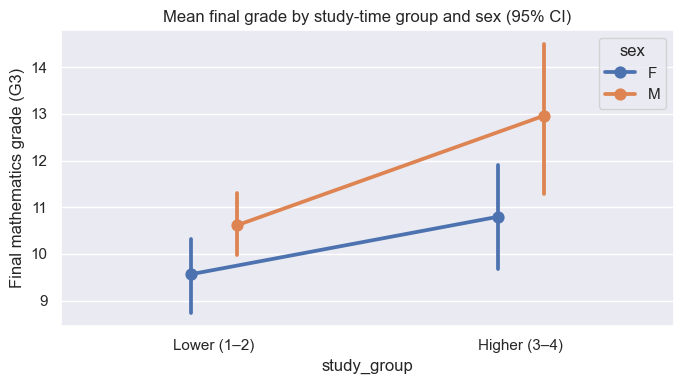

In [8]:
cell_counts = pd.crosstab(analysis["study_group"], analysis["sex"])
print("Counts by study group and sex:")
display(cell_counts)
two_way_model = ols("G3 ~ C(study_group) * C(sex)", data=analysis).fit()
two_way_table = anova_lm(two_way_model, typ=2)
display(two_way_table)
plt.figure(figsize=(7, 4))
sns.pointplot(data=analysis, x="study_group", y="G3", hue="sex", errorbar=("ci", 95), dodge=0.15)
plt.title("Mean final grade by study-time group and sex (95% CI)")
plt.ylabel("Final mathematics grade (G3)")
plt.tight_layout()
plt.show()


## 8. Findings and limitations

Use the actual outputs above to write a short findings summary. Do not invent results.

Include:
1. Which normality tests rejected normality at α = 0.05.
2. Welch t-test p-value and 95% confidence interval for the mean difference.
3. Mann–Whitney U p-value.
4. One-way ANOVA p-value and relevant Tukey HSD comparisons.
5. Two-way ANOVA p-values for study group, sex, and interaction.
6. Limitations: observational data, categorical self-reported study time, possible confounding, and limited generalizability.

**Conclusion template:** “In this dataset, [describe observed association]. The result [was/was not] statistically significant at α = 0.05. Because the data are observational, the analysis does not establish causation.”


## 9. Reproducibility record

- Dataset source: UCI Student Performance repository (link in project README).
- Raw file: `data/raw/student-mat.csv`.
- Package versions: `requirements.txt`; record exact installed versions in `requirements-lock.txt`.
- Run all notebook cells from top to bottom.
- Record deviations from the planned analysis with date and reason.
